# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [42]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
import pandas as pd

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [44]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [45]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [46]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [47]:
# revisar el número de filas y columnas de cada dataset
print("Dimensiones de plans:", plans.shape)
print("Dimensiones de users:", users.shape)
print("Dimensiones de usage:", usage.shape)
print("\n" + "="*50 + "\n")

Dimensiones de plans: (2, 8)
Dimensiones de users: (4000, 8)
Dimensiones de usage: (40000, 6)




In [48]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [49]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [50]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [51]:


# cantidad de nulos para users
print("Cantidad de valores nulos:\n", users.isna().sum())
print("\nProporción de valores nulos:\n", users.isna().mean())



Cantidad de valores nulos:
 user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
 user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [52]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:\n", usage.isna().sum())
print("\nProporción de valores nulos:\n", usage.isna().mean())

Cantidad de valores nulos:
 id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
 id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  
En users: city tiene 469 valores faltantes (11.73%) y churn_date tiene 3,534 valores faltantes (88.35%).

En usage: date tiene 50 valores faltantes (0.13%), duration tiene 22,076 valores faltantes (55.19%) y length tiene 17,896 valores faltantes (44.74%).
  
- Indica qué harías: ¿imputar, eliminar, ignorar?
  
users['city'] (11.73%): Investigaría si es posible inferir la ciudad con otras fuentes o imputaría los faltantes como "Desconocida" para no perder registros relevantes al segmentar por ubicación.

users['churn_date'] (88.35%): Ignoraría los valores nulos y los dejaría intactos, ya que representan usuarios que siguen activos en el servicio y no han cancelado.

usage['date'] (0.13%): Eliminaría esas 50 filas o las imputaría si es posible reconstruir la fecha, ya que representan una proporción mínima del total y no afectan el análisis general.

usage['duration'] (55.19%) y usage['length'] (44.74%): Ignoraría los nulos y los dejaría como están, porque ambos campos son mutuamente excluyentes según el tipo de evento (type): cuando un registro es un mensaje (text), duration es nulo por naturaleza, y cuando es una llamada (call), length queda vacío.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [53]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` tiene un rango normal y secuencial que va desde 10000 hasta 13999 para los 4,000 usuarios, sin presentar valores atípicos, negativos ni errores evidentes.
- La columna `age` presenta un valor mínimo inválido de -999.0, el cual funciona como un valor sentinel para representar edades desconocidas o no registradas; este valor está distorsionando artificialmente tanto la media (33.74) como la desviación estándar (123.23), mientras que el resto de las edades válidas se distribuye entre los 32 años (percentil 25) y un máximo de 79 años.

In [54]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`tienen rangos normales y secuenciales (id va de 1 a 40000 como identificador único de cada evento y user_id va de 10000 a 13999, coincidiendo con los usuarios registrados), sin presentar valores inválidos ni sentinels.

  
- Las columnas `duration` y `length` no muestran valores sentinels negativos, pero ambas parten desde 0.0 (llamadas sin duración o mensajes vacíos) y alcanzan máximos muy elevados (120.0 minutos en duration y 1490.0 caracteres en length) frente a sus percentiles 75 (6.99 y 64.0), lo que evidencia una fuerte asimetría positiva y posibles valores atípicos (outliers).

In [55]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"--- Valores únicos en {col} ---")
    print(users[col].value_counts(dropna=False))
    print("\n")


--- Valores únicos en city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


--- Valores únicos en plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64




- La columna `city` además de los 469 nulos (NaN), aparece el carácter ? en 96 registros, el cual funciona como un valor sentinel para representar ciudades desconocidas.

  
- La columna `plan` solo existen dos categorías limpias y válidas (Basico y Premium), sin errores ni valores raros.

In [56]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` contiene únicamente dos categorías limpias y válidas (text con 22,092 registros y call con 17,908 registros), sin valores nulos, espacios extra ni caracteres sentinel.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

users['age']: Contiene el valor -999.0, un sentinel que representa edades no registradas y que distorsiona el promedio y la desviación estándar de la variable.

users['city']: Presenta el carácter ? en 96 registros como valor sentinel para ciudades desconocidas, además de los 469 valores nulos (NaN) ya detectados.

- ¿Qué acción tomarías?

Para users['age']: Reemplazaría todos los valores -999 por NaN (valores nulos estándar) para que no distorsionen los cálculos estadísticos y luego evaluaría si conviene imputarlos con la mediana de edad o mantenerlos como nulos según el análisis.

Para users['city']: Reemplazaría el carácter ? por NaN para estandarizar todos los datos faltantes bajo un mismo formato y posteriormente los agruparía en una categoría como "Desconocida" si se requiere incluir esos registros en segmentaciones por ubicación.
  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [57]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [58]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [59]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, la mayoría de los registros se distribuyen de manera uniforme entre los años válidos del estudio: 2022 (1,314 usuarios), 2023 (1,316 usuarios) y 2024 (1,330 usuarios); sin embargo, se detectaron 40 registros con el año 2026, lo cual constituye una fecha imposible o fuera de rango dado que la información disponible abarca únicamente hasta 2024.

In [60]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, se registran 39,950 eventos correspondientes de manera consistente al año 2024 y 50 valores nulos (NaN / NaT) que ya habían sido detectados previamente en el análisis de valores faltantes, sin presencia de fechas futuras ni años fuera de rango. Basaremos el análisis en estas fechas.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?

users['reg_date']: Sí, aparecen 40 registros con el año 2026, lo cual es una fecha imposible/futura considerando que los datos recopilados llegan únicamente hasta el año 2024. El resto de los registros se distribuyen correctamente entre 2022 (1,314), 2023 (1,316) y 2024 (1,330).

usage['date']: No aparecen años fuera de rango; todos los registros válidos pertenecen al año 2024 (39,950 registros) y los 50 restantes corresponden a valores nulos (NaT) ya detectados previamente.
  
- ¿Qué harías con ellas?

Para users['reg_date']: Reemplazaría las 40 fechas del año 2026 por NaT (valores nulos de fecha) para evitar que fechas futuras distorsionen cálculos de antigüedad, cohortes o análisis temporales de registro. Si se requiere analizar el uso de esos 40 usuarios en usage, conservaría sus registros de actividad marcando su fecha de alta como desconocida (NaT) en lugar de eliminar al usuario completo.

Para usage['date']: Mantendría los 50 registros con NaT documentados como fechas faltantes (o los excluiría únicamente en análisis agrupados por fecha o mes, ya que representan apenas el 0.125% del total de eventos).


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [61]:
# Reemplazar -999 por la mediana de age

age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [62]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [63]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [64]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).agg(
    nulos='sum',
    total='count',
    porcentaje_nulos=lambda x: x.mean() * 100
)


,nulos,total,porcentaje_nulos
type,,,
call,0,17908,0.000000
text,22076,22092,99.927576


In [65]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).agg(
    nulos='sum',
    total='count',
    porcentaje_nulos=lambda x: x.mean() * 100
)


,nulos,total,porcentaje_nulos
type,,,
call,17896,17908,99.932991
text,0,22092,0.000000


Diagnóstico de valores nulos en `duration` y `length`:

Se confirma que los valores faltantes en ambas columnas siguen un mecanismo MAR (Missing At Random), ya que dependen directamente de la variable observada type:

En `duration`: El 0% de los registros de tipo call (0 de 17,908) son nulos, mientras que el 99.93% de los registros de tipo text (22,076 de 22,092) son nulos. Esto es completamente esperado porque los mensajes de texto no tienen duración en minutos.

En `length`: El 0% de los registros de tipo text (0 de 22,092) son nulos, mientras que el 99.93% de los registros de tipo call (17,896 de 17,908) son nulos, dado que las llamadas de voz no tienen longitud en caracteres.

Decisión y justificación:

Se decide mantener los valores nulos (NaN) sin imputarlos ni eliminarlos. Imputar estos campos con 0 o con la mediana introduciría datos artificiales en eventos donde la métrica no aplica, distorsionando el cálculo de promedios y distribuciones reales para cada tipo de servicio.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [66]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
    .agg(
        cant_mensajes=("is_text", "sum"),
        cant_llamadas=("is_call", "sum"),
        cant_minutos_llamada=("duration", "sum"),
    )
    .reset_index()
)

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [67]:


# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left").fillna({
    "cant_mensajes": 0,
    "cant_llamadas": 0,
    "cant_minutos_llamada": 0
})
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [71]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [72]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

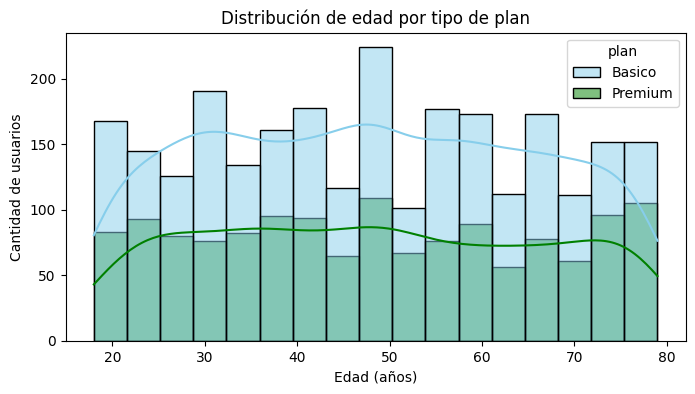

In [73]:
# Histograma para visualizar la edad (age)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], kde=True)
plt.title("Distribución de edad por tipo de plan")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución uniforme y simétrica: La edad de los usuarios se distribuye de manera bastante uniforme (sin sesgos pronunciados hacia la izquierda o derecha) en un rango aproximado de entre 18 y 79 años.
  
- Comportamiento por plan: No existe una diferencia demográfica por edad entre quienes eligen el plan Básico y el Premium; ambos grupos mantienen proporciones muy estables a lo largo de todas las franjas etarias (con un ligero pico cercano a los 48-50 años). La única diferencia visible es el volumen total, ya que el plan Básico concentra aproximadamente el doble de usuarios que el Premium en cada rango de edad.

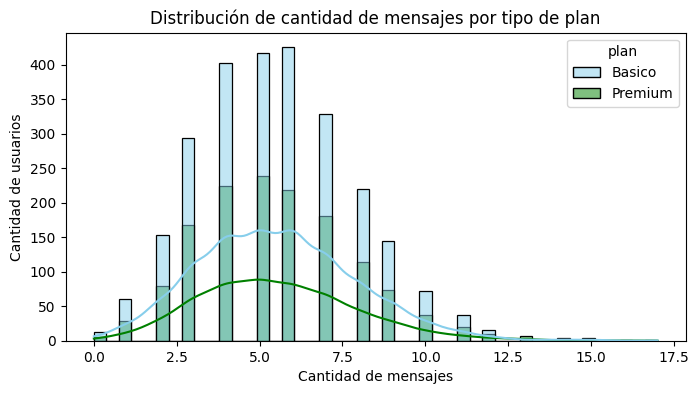

In [74]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], kde=True)
plt.title("Distribución de cantidad de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Tipo de distribución: Presenta una distribución ligeramente sesgada a la derecha (asimetría positiva), con la mayor concentración de usuarios enviando entre 4 y 6 mensajes, y una cola que se extiende gradualmente hasta alrededor de los 17 mensajes.

Comportamiento por plan: No existe un patrón diferenciado en el hábito de envío de mensajes según el tipo de plan. Tanto los usuarios del plan Básico como los del Premium muestran prácticamente la misma mediana y dispersión centradas alrededor de los 5 mensajes; la única diferencia es la frecuencia absoluta debido a que hay más clientes en el plan Básico.

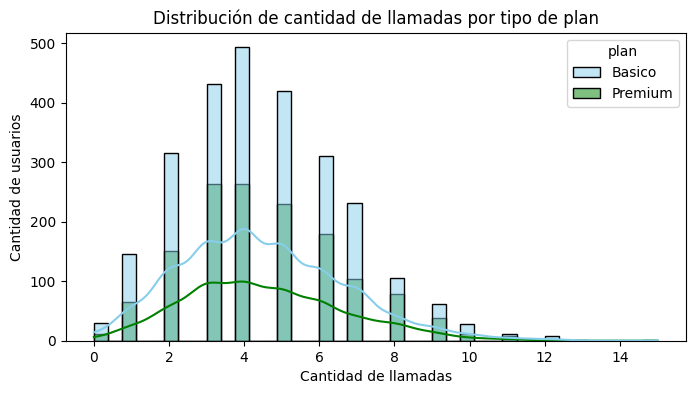

In [75]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], kde=True)
plt.title("Distribución de cantidad de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Tipo de distribución: Presenta una distribución sesgada a la derecha (asimetría positiva), con un pico marcado alrededor de las 3 a 5 llamadas y una cola larga que se extiende hacia la derecha hasta aproximadamente 14 o 15 llamadas.

- Comportamiento por plan: No existe un patrón diferenciado en la cantidad de llamadas realizadas según el tipo de plan. Tanto los usuarios del plan Básico como los del Premium concentran su actividad en el mismo rango (alrededor de 4 llamadas en promedio), reflejando únicamente una mayor cantidad total de clientes en el plan Básico.

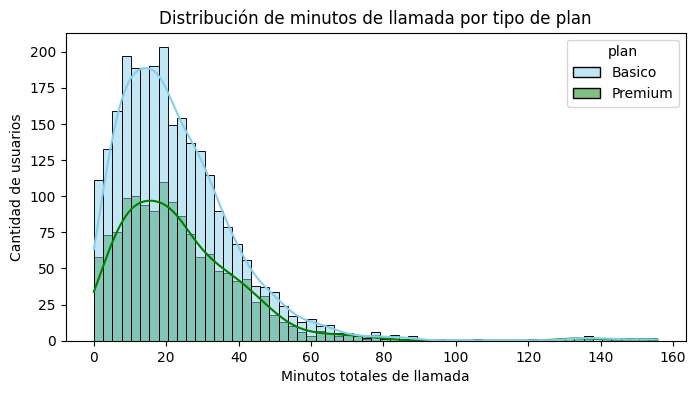

In [76]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], kde=True)
plt.title("Distribución de minutos de llamada por tipo de plan")
plt.xlabel("Minutos totales de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Tipo de distribución: Presenta una distribución fuertemente sesgada a la derecha (asimetría positiva), con la mayor concentración de usuarios acumulando entre 10 y 25 minutos de llamada y una cola larga hacia la derecha que alcanza valores extremos cercanos a los 150-160 minutos.

- Comportamiento por plan: No se observa una diferencia significativa en la duración total de las llamadas entre los usuarios del plan Básico y el Premium; ambas distribuciones comparten un pico central muy similar (alrededor de los 15-20 minutos), diferenciándose únicamente por el mayor volumen total de usuarios en el plan Básico.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

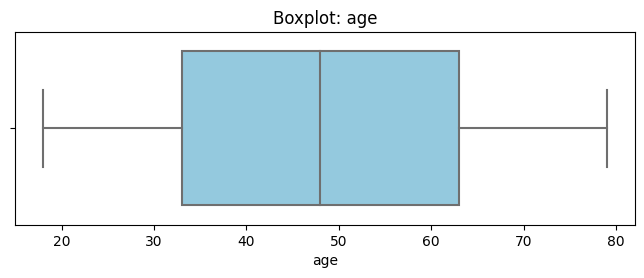

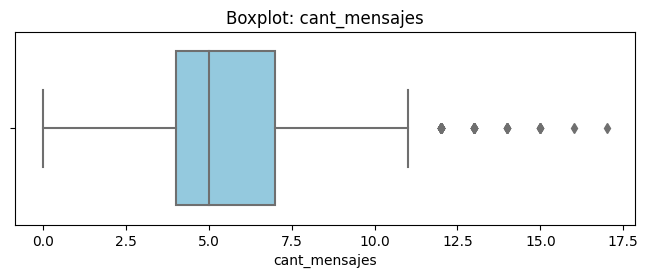

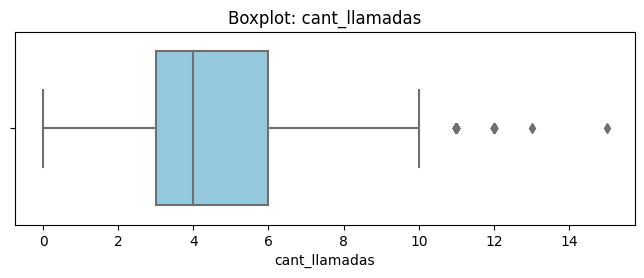

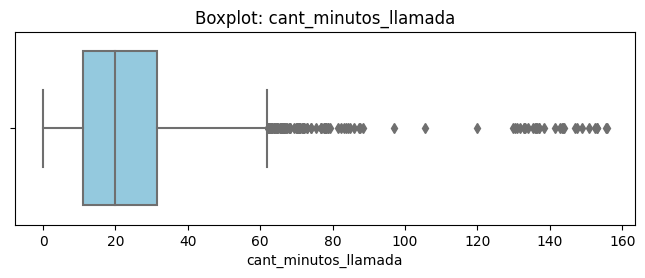

In [77]:
# Visualizando mediante BoxPlots
columnas_boxplot = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_boxplot:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(data=user_profile, x=col, color="skyblue")
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

💡Insights: 

La variable age no presenta valores atípicos.

Las variables de actividad (cant_mensajes, cant_llamadas y cant_minutos_llamada) sí presentan outliers únicamente en el extremo superior (cola derecha), siendo cant_minutos_llamada la que concentra mayor cantidad de valores extremos.

- Age:  No presenta outliers; todos los datos se encuentran dentro de los bigotes (entre 18 y 79 años) con una distribución simétrica.
- cant_mensajes: Presenta outliers únicamente en el extremo superior (a partir de 12 mensajes aproximadamente)
- cant_llamadas: Presenta outliers únicamente en el extremo superior (a partir de 11 llamadas aproximadamente)
- cant_minutos_llamada:Presenta numerosos outliers en el extremo superior (por encima de los ~62 minutos, extendiéndose hasta cerca de 160 minutos)

In [78]:
# Calcular límites con el método IQR
# Calcular límites con el método IQR
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    max_valor = user_profile[col].max()
    cant_extremos = (user_profile[col] > limite_superior).sum()
    
    print(f"Variable: {col}")
    print(f"  - Límite superior (IQR): {limite_superior:.2f}")
    print(f"  - Valor máximo observado: {max_valor:.2f}")
    print(f"  - Cantidad de usuarios por encima del límite: {cant_extremos}\n")



Variable: cant_mensajes
  - Límite superior (IQR): 11.50
  - Valor máximo observado: 17.00
  - Cantidad de usuarios por encima del límite: 46

Variable: cant_llamadas
  - Límite superior (IQR): 10.50
  - Valor máximo observado: 15.00
  - Cantidad de usuarios por encima del límite: 30

Variable: cant_minutos_llamada
  - Límite superior (IQR): 61.87
  - Valor máximo observado: 155.69
  - Cantidad de usuarios por encima del límite: 109



In [79]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000



💡Insights: 
💡Insights: 
- **cant_mensajes:** **Mantener outliers.** Aunque 46 usuarios superan el límite superior IQR de 11.50 mensajes, el valor máximo es de apenas 17 mensajes (frente a una mediana de 5). Es un comportamiento completamente real y plausible de clientes que usan más el servicio, no un error de registro.
- **cant_llamadas:** **Mantener outliers.** Solo 30 usuarios superan el límite superior IQR de 10.50 llamadas, alcanzando un máximo de 15 llamadas (con una mediana de 4). Representa actividad genuina de usuarios frecuentes dentro del periodo analizado y eliminarlos sesgaría el consumo real a la baja.
- **cant_minutos_llamada:** **Mantener outliers.** Aunque 109 usuarios superan el límite superior de 61.87 minutos llegando hasta un máximo de 155.69 minutos (~2.6 horas en total), son valores totalmente posibles que reflejan a nuestros clientes de alto consumo (*heavy users*). Además, la media (23.31 min) y la mediana (19.78 min) se mantienen cercanas, por lo que estos extremos aportan valor clave para segmentar planes sin distorsionar el análisis general.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [80]:
# Crear columna grupo_uso

import numpy as np

condiciones = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10)
]

categorias = ["Bajo uso", "Uso medio"]

user_profile["grupo_uso"] = np.select(condiciones, categorias, default="Alto uso")

# Verificar los resultados
user_profile[["user_id", "cant_llamadas", "cant_mensajes", "grupo_uso"]].head(10)


,user_id,cant_llamadas,cant_mensajes,grupo_uso
0,10000,3.0,7.0,Uso medio
1,10001,10.0,5.0,Alto uso
2,10002,2.0,5.0,Uso medio
3,10003,3.0,11.0,Alto uso
4,10004,3.0,4.0,Bajo uso
5,10005,7.0,5.0,Uso medio
6,10006,5.0,3.0,Uso medio
7,10007,5.0,3.0,Uso medio
8,10008,5.0,5.0,Uso medio
9,10009,3.0,5.0,Uso medio


In [81]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [83]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60
]

categorias_edad = ["Joven", "Adulto"]

user_profile["grupo_edad"] = np.select(condiciones_edad, categorias_edad, default="Adulto Mayor")


In [84]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

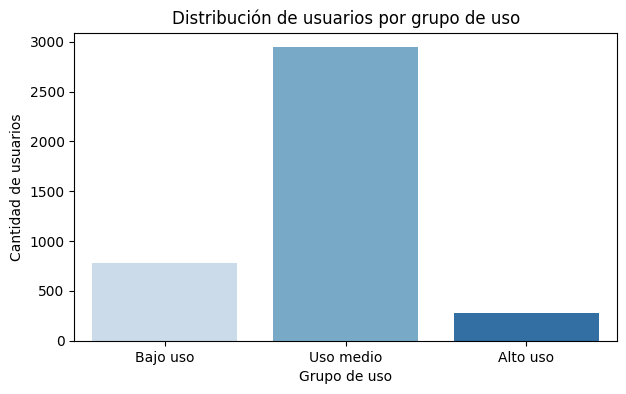

In [85]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    order=["Bajo uso", "Uso medio", "Alto uso"],
    palette="Blues"
)
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

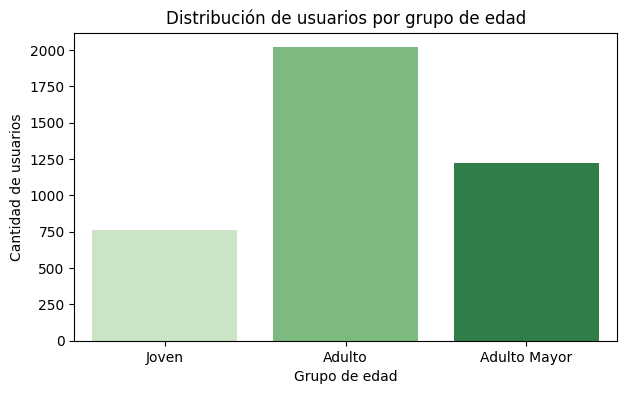

In [86]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x="grupo_edad",
    order=["Joven", "Adulto", "Adulto Mayor"],
    palette="Greens"
)
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**¿Qué problemas tenían originalmente los datos? ¿Qué porcentaje, o cantidad de filas, de esa columna representaban?**
  * **Tabla `users` (4,000 filas):**
    * `churn_date`: Presentaba **3,534 valores nulos (88.35%)**, lo cual es esperado porque corresponde a los usuarios que continúan activos en el servicio.
    * `city`: Contenía **469 valores nulos (`NaN`, 11.73%)** más **96 registros con el carácter sentinela `'?'` (2.40%)**, sumando un total de **565 filas sin ciudad válida (14.13%)**.
    * `age`: Aunque no tenía nulos explícitos, contenía el valor sentinela **`-999.0`**, lo que distorsionaba el promedio (bajándolo a 33.74 años) y disparaba la desviación estándar (123.23); estos valores se convirtieron a `NaN` para limpiar la distribución.
  * **Tabla `usage` (40,000 filas):**
    * `date`: Presentaba **50 valores nulos (0.13%)**.
    * `duration` y `length`: Tenían **22,076 nulos (55.19%)** y **17,896 nulos (44.74%)** respectivamente; son nulos estructurales esperados porque `duration` aplica solo a llamadas (17,924 registros) y `length` solo a mensajes (22,104 registros).
  * **Cruce de tablas (`LEFT JOIN`):** Al unir `users` con el consumo agregado, un grupo menor de usuarios sin tráfico registrado en el periodo quedó con valores nulos en sus métricas de actividad, los cuales se imputaron con `0` para reflejar su inactividad real sin perder sus perfiles.

- **¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?**
  * **Por nivel de uso (`grupo_uso`):** El segmento de **Uso medio** concentra la mayor parte de la cartera con **~74% (~2,950 usuarios)**, seguido por **Bajo uso** con **~19% (~770 usuarios)** y **Alto uso** con **~7% (~280 usuarios)**.
  * **Por grupo de edad (`grupo_edad`):** Predomina el segmento **Adulto (30–59 años)** con **~50% (>2,000 usuarios)**, seguido por **Adulto Mayor (60+ años)** con **~31% (~1,230 usuarios)** y **Joven (<30 años)** con **~19% (~760 usuarios)**.
  * **Comportamiento por plan:** Aunque el plan **Básico** tiene más suscriptores que el **Premium** (2,595 frente a 1,405 usuarios), ambos grupos presentan patrones de consumo prácticamente idénticos (medianas de 5 mensajes, 4 llamadas y ~20 minutos totales).

- **¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**
  * **Usuarios de "Alto uso" en el plan Básico:** Representan la oportunidad comercial más rentable a corto plazo (*upselling*), ya que consumen intensivamente el servicio pero pagan la tarifa base, por lo que son candidatos ideales para migrar al plan Premium.
  * **Segmentos "Adulto" y "Adulto Mayor" de "Uso medio":** Concentran más del 80% de la base instalada y sostienen los ingresos recurrentes y estables de la compañía; fidelizarlos protege la rentabilidad central del negocio.

- **¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?**
  Se identificaron valores atípicos únicamente en el extremo superior de las tres variables de uso: `cant_mensajes` (**46 usuarios** > 11.50, máx. 17), `cant_llamadas` (**30 usuarios** > 10.50, máx. 15) y `cant_minutos_llamada` (**109 usuarios** > 61.87 min, máx. 155.69 min). Todos corresponden a consumo legítimo de usuarios intensivos (*heavy users*), por lo que se conservaron. Para el negocio, esto confirma que existe una demanda real de paquetes de voz de larga duración (60 a 155+ minutos) que actualmente no está monetizada mediante planes diferenciados.

- **¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**
  * **Campaña de *upselling* para *heavy users*:** Ofrecer incentivos de migración al plan **Premium** a los usuarios de **Alto uso** (y a los 109 usuarios con más de 60 minutos de llamada) que hoy pertenecen al plan Básico.
  * **Rediseñar la propuesta de valor del plan Premium:** Dado que hoy los clientes Premium consumen igual que los del plan Básico, se deben incorporar beneficios tangibles (bonos de minutos extra, datos ilimitados o atención prioritaria) para justificar su precio y reducir el *churn*.
  * **Crear un plan "Esencial / Senior":** Diseñar una tarifa competitiva enfocada en voz y mensajería básica para fidelizar al sólido segmento de **Adultos Mayores (~31%)** y retener al grupo de **Bajo uso (~19%)**.
  * **Lanzar un plan orientado al segmento Joven (<30 años):** Dado que representan solo el ~19% de la cartera, incluir paquetes atractivos de datos móviles y redes sociales para captar nuevos clientes jóvenes y rejuvenecer la base.


### 📊 Resumen Ejecutivo – Análisis de Clientes y Patrones de Uso (ConnectaTel)

**Contexto y Calidad de Datos:**
Se analizó una base de **4,000 clientes** (`users`) y **40,000 registros de actividad** (`usage`). Durante la limpieza se estandarizaron valores faltantes y sentinela —destacando un 14.13% de registros sin ciudad válida (`NaN` y `'?'`), edades inválidas (`-999`) y 50 fechas nulas en uso— y se imputaron en `0` los usuarios sin actividad registrada, preservando el 100% de la muestra para el análisis.

**Hallazgos Clave:**
* **Composición de la Cartera:** El negocio está sostenido principalmente por usuarios de **Uso medio (~74%)** y por los segmentos etarios **Adulto (30–59 años, ~50%)** y **Adulto Mayor (60+ años, ~31%)**, mientras que el segmento **Joven (<30 años)** representa apenas el **~19%**.
* **Paridad de Consumo entre Planes:** No existen diferencias significativas en el uso entre los planes **Básico** (64.9% de los clientes) y **Premium** (35.1%); ambos presentan medianas casi idénticas (5 mensajes, 4 llamadas y ~20 minutos totales).
* **Nicho de Usuarios Intensivos (*Heavy Users*):** Se detectaron valores atípicos legítimos en el extremo superior —destacando **109 usuarios** que superan los 61.8 minutos de llamada (hasta 155.7 min)— que representan una demanda de alto consumo aún no capitalizada.

**Acciones Estratégicas Recomendadas:**
1. **Campaña de *Upselling*:** Migrar al plan Premium a los clientes de **Alto uso (~7%)** y *heavy users* de minutos que actualmente pagan la tarifa Básica.
2. **Rediseño del Plan Premium:** Incorporar beneficios diferenciadores (bonos de minutos o datos) que justifiquen su precio frente al plan Básico y reduzcan el riesgo de cancelación.
3. **Segmentación Comercial:** Crear un plan **Esencial/Senior** para fidelizar a los Adultos Mayores y lanzar ofertas enfocadas en datos móviles para captar al segmento Joven.


### Análisis ejecutivo


⚠️ **Problemas detectados en los datos**
- En la tabla `users` (4,000 registros), `churn_date` presentó 3,534 valores nulos (88.35%, esperados para usuarios activos), mientras que `city` tuvo 469 nulos (`NaN`, 11.73%) y 96 registros con el carácter sentinela `'?'` (2.40%), sumando un 14.13% de ubicaciones faltantes; además, `age` contenía valores sentinela `-999.0` que distorsionaban la media y se convirtieron a `NaN`.
- En la tabla `usage` (40,000 registros), se detectaron 50 valores nulos en `date` (0.13%), nulos estructurales esperados en `duration` (55.19%) y `length` (44.74%) según el tipo de evento, y un grupo menor de usuarios sin tráfico registrado tras el cruce (`LEFT JOIN`) que se imputó con `0`.

🔍 **Segmentos por Edad**
- **Adulto (30–59 años):** Es el grupo dominante de la cartera con aproximadamente el **50%** de los clientes (>2,000 usuarios), impulsando el mayor volumen de actividad en la plataforma.
- **Adulto Mayor (60+ años) y Joven (<30 años):** Los adultos mayores representan un sólido **~31%** (~1,230 usuarios) con hábitos de consumo estables, mientras que los jóvenes son el segmento minoritario con apenas el **~19%** (~760 usuarios).

📊 **Segmentos por Nivel de Uso**
- **Uso medio (~74% | ~2,950 usuarios):** Constituye el núcleo principal del negocio, manteniendo un consumo regular de entre 5 y 9 llamadas o mensajes.
- **Bajo uso (~19% | ~770 usuarios) y Alto uso (~7% | ~280 usuarios):** El segmento de bajo uso muestra actividad mínima, mientras que el grupo de alto uso (junto con los 109 *heavy users* que superan los 61.8 minutos de llamada) concentra el consumo más intensivo y las mayores oportunidades de monetización.

➡️ **Esto sugiere que** la base actual de ConnectaTel depende fuertemente de clientes adultos y de consumo moderado, pero existe una desconexión entre el nivel de uso y el tipo de plan contratado (los planes Básico y Premium tienen medianas de consumo casi idénticas, mientras que varios usuarios intensivos siguen pagando tarifas básicas).

💡 **Recomendaciones**
- **Ejecutar campañas de *upselling*:** Migrar hacia el plan Premium a los usuarios de **Alto uso** y *heavy users* de minutos que actualmente están suscritos al plan Básico, ofreciendo paquetes ampliados de voz.
- **Diferenciar el plan Premium y diversificar la oferta:** Añadir beneficios tangibles al plan Premium (bonos de minutos o datos) para justificar su precio, crear un plan **Esencial/Senior** para fidelizar al segmento Adulto Mayor (~31%) y lanzar ofertas centradas en datos móviles para captar al público Joven (<30 años).

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`